In [29]:
import pandas as pd

In [30]:
path = "./runs.csv"

In [31]:
df = pd.read_csv(path)

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 22 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   run                                                144 non-null    str    
 1   experiment                                         144 non-null    str    
 2   date                                               144 non-null    str    
 3   duration                                           144 non-null    str    
 4   training_time_seconds                              144 non-null    float64
 5   meta.dataset                                       144 non-null    str    
 6   meta.model                                         144 non-null    str    
 7   n_params                                           144 non-null    int64  
 8   dataset.use_time_features                          144 non-null    bool   
 9   decoder_outputs_scale

In [33]:
unique_models = df["meta.model"].value_counts()
for model in unique_models.index:
    print(model.replace("\"", ""))

HN-only-1st-BNSATT-NoPE-MGCN-LSTM
HN-only-1st-BNSATT-NoPE-MGAT-LSTM
Shared-only-1st-BNSATT-NoPE-MGAT-LSTM
HN-only-1st-BNSATT-NoPE-MGCNSKIPCONN-LSTM
Shared-only-1st-BNSATT-NoPE-MGCNSKIPCONN-LSTM
Shared-only-1st-BNSATT-NoPE-MGCN-LSTM
HN-only-1st-BNSATT-NoPE-GAT-LSTM
Shared-only-1st-BNSATT-NoPE-GAT-LSTM
HN-only-1st-BNSATT-NoPE-GCNSKIPCONN-LSTM
Shared-only-1st-BNSATT-NoPE-GCNSKIPCONN-LSTM
HN-only-1st-BNSATT-NoPE-GCN-LSTM
Shared-only-1st-BNSATT-NoPE-GCN-LSTM
MGAT-LSTM
MGCNSKIPCONN-LSTM
MGCN-LSTM
GAT-LSTM
GCNSKIPCONN-LSTM
GCN-LSTM
HSAR-Shared-only-1st-BNSATT-NoPE-MGCN-LSTM-SH
HSAR-HN-only-1st-BNSATT-NoPE-MGAT-LSTM-SH
HSAR-Shared-only-1st-BNSATT-NoPE-MGAT-LSTM-SH
HSAR-HN-only-1st-BNSATT-NoPE-MGAT-LSTM-RH
HSAR-Shared-only-1st-BNSATT-NoPE-MGAT-LSTM-RH
HSAR-HN-only-1st-BNSATT-NoPE-MGAT-LSTM-CH
HSAR-Shared-only-1st-BNSATT-NoPE-MGAT-LSTM-CH
HSAR-HN-only-1st-BNSATT-NoPE-MGCNSKIPCONN-LSTM-SH
HSAR-Shared-only-1st-BNSATT-NoPE-MGCNSKIPCONN-LSTM-SH
HSAR-HN-only-1st-BNSATT-NoPE-MGCNSKIPCONN-LSTM-RH
HSAR-

In [34]:
df.columns

Index(['run', 'experiment', 'date', 'duration', 'training_time_seconds',
       'meta.dataset', 'meta.model', 'n_params', 'dataset.use_time_features',
       'decoder_outputs_scaled_mae subset="validation" ',
       'decoder_outputs_scaled_mae subset="test" ',
       'decoder_outputs_scaled_smape subset="validation" ',
       'decoder_outputs_scaled_smape subset="test" ',
       'decoder_outputs_scaled_rmse subset="validation" ',
       'decoder_outputs_scaled_rmse subset="test" ',
       'decoder_outputs_raw_mae subset="validation" ',
       'decoder_outputs_raw_mae subset="test" ',
       'decoder_outputs_raw_smape subset="validation" ',
       'decoder_outputs_raw_smape subset="test" ',
       'decoder_outputs_raw_rmse subset="validation" ',
       'decoder_outputs_raw_rmse subset="test" ', 'dvc_exp_id'],
      dtype='str')

In [35]:
import re


regex = r"(?P<data_distribution>HSAR-)?(NormFF-)?((?P<attention_type>(?P<proj_type>HN|Shared)-(?P<att_state>only-1st|only-2nd|only-3rd|all)-(?P<att_fold>BN)SATT-(?P<pe>RoPE|NoPE))-)?(?P<cell_type>(?P<has_memory>M)?(?P<gnn_type>(GAT|GCN|GCNSKIPCONN))-LSTM)(?P<postprocessing_type>-(RH|CH|SH))?"

for row in df.iterrows():
    model_name = row[1]["meta.model"].replace("\"", "")
    result = re.match(regex, model_name)
    if result is not None:
        df.loc[row[0], "attention_type"] = result.group("attention_type")
        df.loc[row[0], "proj_type"] = result.group("proj_type")
        df.loc[row[0], "att_state"] = result.group("att_state")
        df.loc[row[0], "att_fold"] = result.group("att_fold")
        df.loc[row[0], "pe"] = result.group("pe")
        cell_type = result.group("cell_type")
        df.loc[row[0], "cell_type"] = cell_type
        df.loc[row[0], "gnn_type"] = result.group("gnn_type")
        df.loc[row[0], "postprocessing_type"] = result.group("postprocessing_type")

        # check if result has the group "data_distribution"
        if result.group("data_distribution") is not None:
            df.loc[row[0], "data_distribution"] = "different"
        else:
            df.loc[row[0], "data_distribution"] = "same"

        if any(cell in cell_type for cell in ["GAT-LSTM", "GCN-LSTM", "GCNSKIPCONN-LSTM"]):
            if result.group("has_memory") is not None:
                df.loc[row[0], "has_memory"] = True
            else:
                df.loc[row[0], "has_memory"] = False
    else:
        print(f"Model: {model_name} does not match the regex.")

In [36]:
df

,run,experiment,date,duration,training_time_seconds,meta.dataset,meta.model,n_params,dataset.use_time_features,"decoder_outputs_scaled_mae subset=""validation""",...,attention_type,proj_type,att_state,att_fold,pe,cell_type,gnn_type,postprocessing_type,data_distribution,has_memory
0,Run: 504aec8bdd644ab88a2e76a7,validation-beijing-multisite-airquality-HN-onl...,"22:36:42 · 21 Oct, 26",4sec 850ms,13.806232,"""beijing-multisite-airquality""","""HN-only-1st-BNSATT-NoPE-MGCN-LSTM""",28952,False,0.031147,...,HN-only-1st-BNSATT-NoPE,HN,only-1st,BN,NoPE,MGCN-LSTM,GCN,None,same,True
1,Run: 24aa6f0ef135487ca3fb40f7,validation-beijing-multisite-airquality-HN-onl...,"22:32:29 · 21 Oct, 26",46sec 854ms,36.297559,"""beijing-multisite-airquality""","""HN-only-1st-BNSATT-NoPE-MGAT-LSTM""",71080,True,0.026223,...,HN-only-1st-BNSATT-NoPE,HN,only-1st,BN,NoPE,MGAT-LSTM,GAT,None,same,True
2,Run: 20f72afc1f3c4cedbec1764d,validation-beijing-multisite-airquality-Shared...,"22:31:45 · 21 Oct, 26",44sec 400ms,33.880883,"""beijing-multisite-airquality""","""Shared-only-1st-BNSATT-NoPE-MGAT-LSTM""",17120,True,0.027143,...,Shared-only-1st-BNSATT-NoPE,Shared,only-1st,BN,NoPE,MGAT-LSTM,GAT,None,same,True
3,Run: 7b4c4229c7ce4c119ec19af0,validation-beijing-multisite-airquality-HN-onl...,"22:31:07 · 21 Oct, 26",37sec 776ms,26.840001,"""beijing-multisite-airquality""","""HN-only-1st-BNSATT-NoPE-MGAT-LSTM""",34048,False,0.029060,...,HN-only-1st-BNSATT-NoPE,HN,only-1st,BN,NoPE,MGAT-LSTM,GAT,None,same,True
4,Run: 3f74c46ac0154a96bf08bbc7,validation-beijing-multisite-airquality-Shared...,"22:30:32 · 21 Oct, 26",35sec 24ms,25.676870,"""beijing-multisite-airquality""","""Shared-only-1st-BNSATT-NoPE-MGAT-LSTM""",8204,False,0.029173,...,Shared-only-1st-BNSATT-NoPE,Shared,only-1st,BN,NoPE,MGAT-LSTM,GAT,None,same,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,Run: bdd3e4fc6fd3409e9caabf43,validation-beijing-multisite-airquality-HSAR-G...,"17:43:55 · 21 Oct, 26",16sec 734ms,8.904117,"""beijing-multisite-airquality""","""HSAR-GCN-LSTM-RH""",5788,True,0.051577,...,NaN,NaN,NaN,NaN,NaN,GCN-LSTM,GCN,-RH,different,False
140,Run: 477885db806c4fabb0a5a682,validation-beijing-multisite-airquality-HSAR-G...,"17:43:39 · 21 Oct, 26",16sec 509ms,9.176041,"""beijing-multisite-airquality""","""HSAR-GCN-LSTM-CH""",3090,True,0.047719,...,NaN,NaN,NaN,NaN,NaN,GCN-LSTM,GCN,-CH,different,False
141,Run: f60f4bc475a640eab5d4b637,validation-beijing-multisite-airquality-HSAR-G...,"17:43:22 · 21 Oct, 26",16sec 846ms,7.050653,"""beijing-multisite-airquality""","""HSAR-GCN-LSTM-SH""",1470,False,0.051470,...,NaN,NaN,NaN,NaN,NaN,GCN-LSTM,GCN,-SH,different,False
142,Run: cb925e4d93094ae6a9143071,validation-beijing-multisite-airquality-HSAR-G...,"17:43:04 · 21 Oct, 26",17sec 90ms,7.942636,"""beijing-multisite-airquality""","""HSAR-GCN-LSTM-RH""",3340,False,0.051523,...,NaN,NaN,NaN,NaN,NaN,GCN-LSTM,GCN,-RH,different,False


In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

In [58]:
col = ["data_distribution", "gnn_type"] # ["proj_type", 'dataset.use_time_features', "data_distribution", "postprocessing_type"]
# replace None with "None"

if isinstance(col, list):
    for c in col:
        df[c] = df[c].fillna("None")
    df["combination"] = df[col].apply(lambda x: "-".join(x.astype(str)), axis=1)
    col = "combination"
else:
    df[col] = df[col].fillna("None")

df[col].value_counts()

combination
different-GCN            36
different-GAT            36
different-GCNSKIPCONN    36
same-GCN                 12
same-GAT                 12
same-GCNSKIPCONN         12
Name: count, dtype: int64

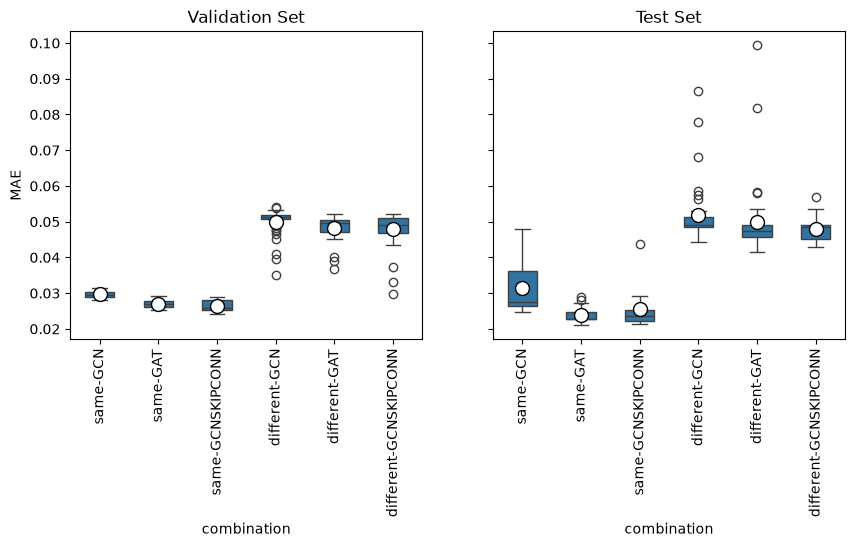

In [61]:
# show boxplots of the decoder_outputs_scaled_mae for each attention_type in both validation and test, using only the test subset
# show also the mean and median line in the same plot, using a different color for each
# the left plot is for valdiation while the right plot is for test

metric = "mae"

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
sns.boxplot(
    data=df, 
    x=col, 
    y=f'decoder_outputs_scaled_{metric} subset="validation" ',
    showmeans=True,
    width=0.5,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"10"},
    ax=axes[0],
)

axes[0].set_title("Validation Set")
axes[0].set_ylabel(metric.upper())

sns.boxplot(
    data=df, 
    x=col, 
    y=f'decoder_outputs_scaled_{metric} subset="test" ',
    showmeans=True,
    width=0.5,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"10"},
    ax=axes[1],
)

axes[1].set_title("Test Set")
axes[1].set_ylabel(metric.upper())

for ax in axes:
    ax.tick_params(axis='x', rotation=90)

# plt.tight_layout()
plt.show()

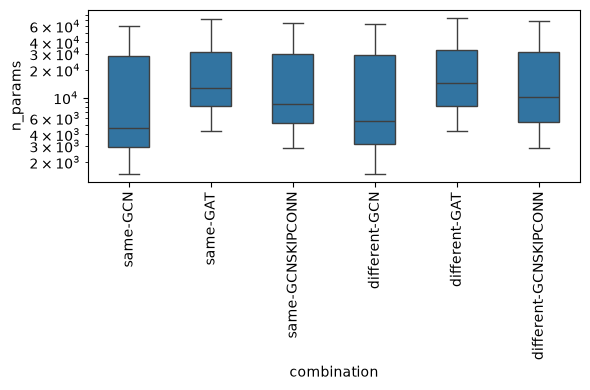

In [60]:
fig = plt.figure(figsize=(6, 4))
axis = plt.gca()
axis.tick_params(axis='x', rotation=90)
sns.boxplot(
    data=df, 
    x=col, 
    y='n_params',
    # use log scale for y axis
    width=0.5,
    log_scale=True
)
plt.tight_layout()
plt.show()